**Knowledge Engineering**
**: Autonomous Trailer Knowledge-Based Agent (Nairobi to Kisumu)**

****

*Template adapted from [Zainabu Muti](https://www.linkedin.com/in/zainabu-muti-3789591b3/)*

This notebook turns the self-driving trailer from Practical Exercise 3 into a **knowledge-based
agent**. The trailer keeps a knowledge base (KB) of facts and rules about the Kenyan road network,
the weather, traffic law and its own state. It **infers** new facts by forward chaining and answers
questions such as *"which route should I take?"*, *"how fast may I drive on this leg?"* and *"why?"*.

| Repository file | Purpose |
|---|---|
| `Autonomous_Trailer.ipynb` | This notebook: the agent |
| `build_kb.py` | API script that assembles the static knowledge (Step 2) |
| `kb_data.json` | The knowledge produced by `build_kb.py` |

**Step 1: Identify the Task**

The task is to drive a loaded trailer **safely and efficiently from Nairobi to Kisumu** (or between
any two towns in the network), obeying Kenyan traffic law and reacting to conditions on the road.

The agent must be able to:

* plan the shortest route over the Exercise 3 road graph, and a *safest* route that accounts for
  weather hazards and accident blackspots;
* re-plan when roads close or new hazards are reported;
* decide the legal and safe speed for every leg, and what to do at a traffic light;
* refuse to depart when the trailer is overloaded;
* **explain** every conclusion by showing the facts and rules it used.

**Goal:** reach the destination by the lowest-cost route with minimal risk to the cargo, the
trailer and other road users (the performance measure from the Exercise 3 PEAS description).

**Step 2: Assemble Relevant Knowledge**

The trailer needs to know:

* the towns, the roads between them and their lengths (the Exercise 3 directed graph);
* where each town is and how high it is (for the A* distance heuristic and steep-grade detection);
* real-world driving distances, to check the class distances;
* the current weather at each town;
* traffic regulations (speed limits, maximum vehicle mass, traffic-light rules) and known accident blackspots;
* facts about the trip itself: where the trailer is, where it is going and how heavy it is.

```
APIs and web data used to assemble the knowledge base (all free, no API key, used within their usage policies)
```

| Knowledge | Source | How it is used | Code |
|---|---|---|---|
| Towns, roads, class distances | Practical Exercise 3 graph | `Road(a, b, km)` facts | `build_kb.py` |
| Town coordinates and county | [OpenStreetMap Nominatim](https://nominatim.org/release-docs/latest/api/Search/) (max 1 request/s) | `Location`, `InCounty` facts; straight-line distance | `build_kb.py` |
| Real driving distance and time per road | [OSRM demo server](https://project-osrm.org/docs/v5.24.0/api/) | `RoadOSRM` facts; second distance measure and KB check | `build_kb.py` |
| Town elevation | [Open-Meteo Elevation API](https://open-meteo.com/en/docs/elevation-api) | `Elevation` facts; steep-grade rule | `build_kb.py` |
| Town descriptions | [Wikipedia REST API](https://en.wikipedia.org/api/rest_v1/) | Shown when the user asks about a town | `build_kb.py` |
| **Live** weather (changes, so fetched at run time) | [Open-Meteo Forecast API](https://open-meteo.com/en/docs) | `Weather` facts | the cell below |
| Speed limits | Traffic Act (Cap. 403), Eighth Schedule | `SpeedLimitFor`, `UrbanSpeedLimit` | Step 4 |
| Maximum gross vehicle mass | EAC Vehicle Load Control Act, 2016 | `MaxGVM` | Step 4 |
| Accident blackspots | Encoded by hand from Kenyan news reports and NTSA blackspot lists | `Blackspot` | Step 5 |

`build_kb.py` (same repository) queries the first four APIs and saves the result to
`kb_data.json`, so the notebook runs without hammering the free services. Run
`python build_kb.py` to refresh it. The cell below loads that file (from the repository when opened in
Colab) and fetches the live weather for all 16 towns in one request.

In [ ]:
import heapq
import json
import math
import os
import re
from itertools import count

import matplotlib.pyplot as plt
import pandas as pd
import requests

HEADERS = {"User-Agent": "KnowledgeEngineering-AutonomousTrailer/1.0 (student coursework)"}
KB_FILE = "kb_data.json"
KB_URL = "https://raw.githubusercontent.com/jesse-kariuki/Knowledge-Engineering/main/kb_data.json"


def load_static_knowledge():
    """Knowledge assembled by build_kb.py (Nominatim, OSRM, Open-Meteo Elevation, Wikipedia)."""
    if os.path.exists(KB_FILE):
        with open(KB_FILE, encoding="utf-8") as f:
            return json.load(f), KB_FILE
    response = requests.get(KB_URL, headers=HEADERS, timeout=30)  # e.g. when opened in Colab
    response.raise_for_status()
    return response.json(), KB_URL


# Open-Meteo reports WMO weather codes; map them to the agent's weather constants.
WMO_CODES = {
    0: "Clear", 1: "Clear", 2: "Cloudy", 3: "Cloudy", 45: "Fog", 48: "Fog",
    51: "Drizzle", 53: "Drizzle", 55: "Drizzle", 56: "Drizzle", 57: "Drizzle",
    61: "Rain", 63: "Rain", 65: "HeavyRain", 66: "Rain", 67: "HeavyRain",
    80: "Rain", 81: "Rain", 82: "HeavyRain", 95: "Thunderstorm", 96: "Thunderstorm", 99: "Thunderstorm",
}


def fetch_live_weather(towns):
    """Open-Meteo: current weather at every town in one request. Returns {} when offline."""
    try:
        response = requests.get(
            "https://api.open-meteo.com/v1/forecast",
            params={
                "latitude": ",".join(str(t["lat"]) for t in towns.values()),
                "longitude": ",".join(str(t["lon"]) for t in towns.values()),
                "current": "weather_code,temperature_2m,wind_speed_10m,visibility",
            },
            headers=HEADERS, timeout=30,
        )
        response.raise_for_status()
    except requests.RequestException as error:
        print(f"Live weather unavailable ({error}); continuing without weather facts.")
        return {}
    rows = response.json()
    rows = rows if isinstance(rows, list) else [rows]
    weather = {}
    for town, row in zip(towns, rows):
        now = row["current"]
        weather[town] = {
            "condition": WMO_CODES.get(now["weather_code"], "Other"),
            "wmo_code": now["weather_code"],
            "temp_c": now.get("temperature_2m"),
            "wind_kmh": now.get("wind_speed_10m"),
            "visibility_m": now.get("visibility"),
            "time": now.get("time"),
        }
    return weather


DATA, source = load_static_knowledge()
LIVE_WEATHER = fetch_live_weather(DATA["towns"])

print(f"Static knowledge: {source} (built {DATA['generated_at']})")
for item, origin in DATA["sources"].items():
    print(f"  {item:<15} {origin}")
observed = next(iter(LIVE_WEATHER.values()))["time"] + " UTC" if LIVE_WEATHER else "not available"
print(f"Live weather:      Open-Meteo, {len(LIVE_WEATHER)} towns, observed {observed}")

pd.DataFrame(DATA["towns"]).T[["region", "county", "lat", "lon", "elevation_m"]]

Static knowledge: kb_data.json (built 2026-11-20T19:46:52+00:00)
  roads           Practical Exercise 3 (class road graph)
  coordinates     OpenStreetMap Nominatim (ODbL)
  road_distances  OSRM demo server, OpenStreetMap data (ODbL)
  elevation       Open-Meteo Elevation API (Copernicus DEM)
  descriptions    Wikipedia REST API (CC BY-SA)
Live weather:      Open-Meteo, 16 towns, observed 2026-11-20T19:45 UTC


,region,county,lat,lon,elevation_m
Nairobi,Nairobi,Nairobi,-1.289001,36.817281,1672
Thika,Central Highlands,Kiambu,-1.036648,37.077523,1505
Murang'a,Central Highlands,Murang`a,-0.723656,37.157586,1282
Nyeri,Central Highlands,Nyeri,-0.419296,36.951701,1777
Nanyuki,Central Highlands,Laikipia,0.01403,37.074632,1938
Limuru,Rift Valley,Kiambu,-1.115865,36.63931,2260
Naivasha,Rift Valley,Nakuru,-0.722442,36.438783,1938
Gilgil,Rift Valley,Nakuru,-0.498167,36.3254,2006
Nakuru,Rift Valley,Nakuru,-0.280272,36.071205,1859
Nyahururu,Rift Valley,Laikipia,0.0333,36.3666,2365


**Step 3: Define the Vocabulary**

Facts are tuples `Predicate(arg, ...)`. In Python a fact such as `Road(Nairobi, Limuru, 32)` is the tuple
`("Road", "Nairobi", "Limuru", 32)`. In rules, arguments that start with `?` are variables.

*Constants*

| Kind | Constants |
|---|---|
| Towns (16) | Nairobi, Thika, Murang'a, Nyeri, Nanyuki, Nyahururu, Limuru, Naivasha, Gilgil, Nakuru, Mai Mahiu, Narok, Bomet, Kericho, Ahero, Kisumu |
| Regions | Nairobi, Central Highlands, Rift Valley, Lake Victoria Basin |
| Weather | Clear, Cloudy, Drizzle, Rain, HeavyRain, Fog, Thunderstorm, StrongWind, LowVisibility |
| Signals | Red, Yellow, Green, FlashingYellow, FlashingRed, Off |
| Vehicle | Trailer (class HeavyCommercial) |

*Predicates*

| Predicate | Meaning | Origin |
|---|---|---|
| `Town(t)`, `InRegion(t, r)`, `InCounty(t, c)` | t is a town in region r and county c | Exercise 3, Nominatim |
| `Location(t, lat, lon)`, `Elevation(t, m)` | Position and altitude of t | Nominatim, Open-Meteo |
| `Road(a, b, km)` | A two-way road of km kilometres (class distance) | Exercise 3 |
| `RoadOSRM(a, b, km, min)` | Real driving distance and time for the same road | OSRM |
| `Arc(a, b, km)` | Directed arc of the graph (derived) | rule R1 |
| `Closed(a, b)` | The road between a and b is closed | user / sensors |
| `Passable(a, b, km)` | Arc a to b may be driven (derived) | rule R3 |
| `Weather(t, c)` | Condition c observed at t | Open-Meteo live, user reports |
| `Severe(c)`, `HazardSpeed(c, v)`, `RiskPenalty(c, km)` | c is dangerous, its speed cap, its route penalty | design knowledge |
| `Hazard(t, c)`, `SpeedCap(t, v)`, `ArcRisk(a, b, cause, km)` | Derived risk knowledge | rules R4 to R8 |
| `Blackspot(a, b, name)` | Known accident blackspot on a road | hand-encoded |
| `GradeThreshold(m)`, `SteepGrade(a, b, dz)` | A climb or descent of at least m metres (derived) | rule R9 |
| `Advice(a, b, text)` | Driving advice for an arc (derived) | rules R8, R10, R11 |
| `Vehicle(v)`, `VehicleClass(v, c)`, `GrossMass(v, kg)` | Facts about the trailer | Step 5/6 |
| `SpeedLimitFor(c, v)`, `UrbanSpeedLimit(v)`, `MaxGVM(kg)` | Traffic regulations | Traffic Act, EAC Act |
| `MaxSpeed(v, s)`, `Overloaded(v)`, `ReadyToDepart(v)` | Derived vehicle state | rules R12 to R14 |
| `Signal(col)`, `SignalRule(col, action)`, `Action(a)` | Traffic-light observation and response | rule R15 |
| `At(v, t)`, `Destination(v, t)` | The current trip | Step 6 |

*Distance measures* (from Exercise 3 and the APIs)

| Measure | Used for |
|---|---|
| Class road distance, `Road` km | Default step cost g(n), as in Exercise 3 |
| OSRM driving distance, `RoadOSRM` km | Alternative step cost; checks the class distances |
| Haversine straight-line distance between `Location`s | A* heuristic h(n); checks that no road is shorter than a straight line |

**Step 4: Encode General Knowledge about the Domain** `[3 marks]`

The general knowledge has three parts:

1. **An inference engine.** `KnowledgeBase` stores the told facts and **forward-chains** over the rules until no
   new facts appear. Rules may contain a negated condition (`unless`, negation as failure) and a numeric
   `test`. Every derived fact remembers the rule and premises that produced it, so the agent can explain itself.
2. **Domain facts.** The road graph and geography from Step 2, traffic regulations, the weather knowledge and the
   traffic-light rules.
3. **Rules R1 to R15.** These rules turn the raw facts into decisions. Rules with an `unless` condition come
   after the rules that derive what they negate (R2 before R3, R13 before R14). This stratification keeps negation as failure sound.

In [ ]:
def is_var(term):
    return isinstance(term, str) and term.startswith("?")


def substitute(pattern, bindings):
    return tuple(bindings.get(term, term) if is_var(term) else term for term in pattern)


def unify(pattern, fact, bindings):
    """Match a pattern against a fact, extending the bindings, or return None."""
    if len(pattern) != len(fact):
        return None
    bindings = dict(bindings)
    for term, value in zip(pattern, fact):
        if is_var(term):
            if term in bindings and bindings[term] != value:
                return None
            bindings[term] = value
        elif term != value:
            return None
    return bindings


def fmt(fact):
    return f"{fact[0]}({', '.join(str(arg) for arg in fact[1:])})"


class Rule:
    def __init__(self, name, if_, then, unless=(), test=None, compute=None, note=""):
        self.name, self.if_, self.then, self.unless = name, if_, then, unless
        self.test, self.compute, self.note = test, compute, note

    def __str__(self):
        conditions = [fmt(p) for p in self.if_] + [f"NOT {fmt(p)}" for p in self.unless]
        if self.note:
            conditions.append(self.note)
        return f"IF {' AND '.join(conditions)} THEN {' AND '.join(fmt(p) for p in self.then)}"


class KnowledgeBase:
    def __init__(self):
        self.told = {}    # fact -> where it came from
        self.rules = []
        self.facts = {}   # every fact (told + derived) -> (source or rule name, premises)
        self.index = {}   # predicate -> facts, for fast matching

    # --- TELL ---------------------------------------------------------------
    def tell(self, *fact, source="user"):
        self.told[fact] = source

    def retract(self, *pattern, source=None):
        """Remove told facts matching the pattern (optionally only those from one source)."""
        gone = [f for f, s in self.told.items()
                if unify(pattern, f, {}) is not None and (source is None or s == source)]
        for fact in gone:
            del self.told[fact]
        return gone

    def add_rule(self, name, if_, then, **options):
        self.rules.append(Rule(name, if_, then, **options))

    # --- INFER (forward chaining to a fixed point) ----------------------------
    def _add(self, fact, why):
        self.facts[fact] = why
        self.index.setdefault(fact[0], []).append(fact)

    def _prove(self, patterns, bindings=None, premises=()):
        bindings = bindings or {}
        if not patterns:
            yield bindings, premises
            return
        first, rest = patterns[0], patterns[1:]
        for fact in list(self.index.get(first[0], ())):
            extended = unify(first, fact, bindings)
            if extended is not None:
                yield from self._prove(rest, extended, premises + (fact,))

    def infer(self):
        self.facts, self.index = {}, {}
        for fact, source in self.told.items():
            self._add(fact, (source, ()))
        changed = True
        while changed:
            changed = False
            for rule in self.rules:
                for bindings, premises in list(self._prove(rule.if_)):
                    if any(self.ask(*substitute(p, bindings)) for p in rule.unless):
                        continue
                    if rule.test and not rule.test(bindings):
                        continue
                    if rule.compute:
                        bindings = {**bindings, **rule.compute(bindings)}
                    for pattern in rule.then:
                        fact = substitute(pattern, bindings)
                        if fact not in self.facts:
                            self._add(fact, (rule.name, premises))
                            changed = True
        return self

    # --- ASK -------------------------------------------------------------------
    def ask(self, *pattern):
        """All variable bindings that make the pattern true (empty list = not provable)."""
        return [bindings for bindings, _ in self._prove([pattern])]

    def value(self, *pattern):
        """The value of the single variable in the pattern, or None."""
        var = next(term for term in pattern if is_var(term))
        answers = self.ask(*pattern)
        return answers[0][var] if answers else None

    def explain(self, fact, depth=0):
        """Proof tree: the fact, the rule or source behind it and, recursively, its premises."""
        source, premises = self.facts[fact]
        lines = [f"{'    ' * depth}{fmt(fact)}   <- {source}"]
        for premise in premises:
            lines += self.explain(premise, depth + 1)
        return lines

In [ ]:
kb = KnowledgeBase()

# --- Road network (Exercise 3) and geography (APIs, Step 2) ---------------------------
for town, info in DATA["towns"].items():
    kb.tell("Town", town, source="Exercise 3")
    kb.tell("InRegion", town, info["region"], source="Exercise 3")
    kb.tell("InCounty", town, info["county"], source="Nominatim")
    kb.tell("Location", town, info["lat"], info["lon"], source="Nominatim")
    kb.tell("Elevation", town, info["elevation_m"], source="Open-Meteo")
for road in DATA["roads"]:
    kb.tell("Road", road["a"], road["b"], road["km_class"], source="Exercise 3")
    kb.tell("RoadOSRM", road["a"], road["b"], road["km_osrm"], road["minutes_osrm"], source="OSRM")

# --- Traffic regulations -----------------------------------------------------------------
kb.tell("SpeedLimitFor", "HeavyCommercial", 80, source="Traffic Act Cap 403")
kb.tell("UrbanSpeedLimit", 50, source="Traffic Act Cap 403")
kb.tell("MaxGVM", 56000, source="EAC Vehicle Load Control Act 2016")

# --- Weather knowledge: (condition, speed cap km/h, routing penalty km) ---------------
for condition, cap, penalty in [("Fog", 40, 60), ("LowVisibility", 40, 60), ("Thunderstorm", 50, 80),
                                ("HeavyRain", 60, 40), ("StrongWind", 60, 40)]:
    kb.tell("Severe", condition, source="design")
    kb.tell("HazardSpeed", condition, cap, source="design")
    kb.tell("RiskPenalty", condition, penalty, source="design")
kb.tell("RiskPenalty", "Blackspot", 15, source="design")
kb.tell("GradeThreshold", 450, source="design")

# --- Traffic lights (the class traffic-light agent, adapted to a heavy trailer) ---------
SIGNAL_RULES = {
    "Red": "Stop behind the line and wait for green.",
    "Yellow": "Prepare to stop - a loaded trailer needs a long braking distance, so stop only if it is safe.",
    "Green": "Proceed if the junction is clear; watch the trailer's swept path when turning.",
    "FlashingYellow": "Proceed slowly with caution and give way to pedestrians.",
    "FlashingRed": "Treat as a stop sign: stop, check the intersection, then proceed.",
    "Off": "Signals are down: treat as an uncontrolled junction, slow down and give way.",
}
for colour, action in SIGNAL_RULES.items():
    kb.tell("SignalRule", colour, action, source="Traffic Act / class agent")

# --- Rules -------------------------------------------------------------------------------
kb.add_rule("R1 two-way roads", [("Road", "?a", "?b", "?d")],
            [("Arc", "?a", "?b", "?d"), ("Arc", "?b", "?a", "?d")])
kb.add_rule("R2 closures are two-way", [("Closed", "?a", "?b")], [("Closed", "?b", "?a")])
kb.add_rule("R3 passable arcs", [("Arc", "?a", "?b", "?d")], [("Passable", "?a", "?b", "?d")],
            unless=[("Closed", "?a", "?b")])
kb.add_rule("R4 severe weather", [("Weather", "?t", "?c"), ("Severe", "?c")], [("Hazard", "?t", "?c")])
kb.add_rule("R5 hazard speed cap", [("Hazard", "?t", "?c"), ("HazardSpeed", "?c", "?v")],
            [("SpeedCap", "?t", "?v")])
kb.add_rule("R6 hazard risk",
            [("Passable", "?a", "?t", "?d"), ("Hazard", "?t", "?c"), ("RiskPenalty", "?c", "?p")],
            [("ArcRisk", "?a", "?t", "?c", "?p")])
kb.add_rule("R7 blackspots two-way", [("Blackspot", "?a", "?b", "?n")], [("Blackspot", "?b", "?a", "?n")])
kb.add_rule("R8 blackspot risk", [("Blackspot", "?a", "?b", "?n"), ("RiskPenalty", "Blackspot", "?p")],
            [("ArcRisk", "?a", "?b", "?n", "?p"), ("Advice", "?a", "?b", "?msg")],
            compute=lambda b: {"?msg": f"Accident blackspot ({b['?n']}): slow down, no overtaking"})
kb.add_rule("R9 steep grade",
            [("Arc", "?a", "?b", "?d"), ("Elevation", "?a", "?ea"), ("Elevation", "?b", "?eb"),
             ("GradeThreshold", "?min")],
            [("SteepGrade", "?a", "?b", "?dz")],
            test=lambda b: abs(b["?eb"] - b["?ea"]) >= b["?min"],
            compute=lambda b: {"?dz": b["?eb"] - b["?ea"]}, note="|eb - ea| >= min")
kb.add_rule("R10 descent advice", [("SteepGrade", "?a", "?b", "?dz")], [("Advice", "?a", "?b", "?msg")],
            test=lambda b: b["?dz"] < 0, note="dz < 0",
            compute=lambda b: {"?msg": f"Long descent ({-b['?dz']} m): low gear and engine brake"})
kb.add_rule("R11 climb advice", [("SteepGrade", "?a", "?b", "?dz")], [("Advice", "?a", "?b", "?msg")],
            test=lambda b: b["?dz"] > 0, note="dz > 0",
            compute=lambda b: {"?msg": f"Long climb ({b['?dz']} m): keep left, watch engine temperature"})
kb.add_rule("R12 legal speed", [("VehicleClass", "?v", "?c"), ("SpeedLimitFor", "?c", "?s")],
            [("MaxSpeed", "?v", "?s")])
kb.add_rule("R13 overload", [("GrossMass", "?v", "?m"), ("MaxGVM", "?lim")], [("Overloaded", "?v")],
            test=lambda b: b["?m"] > b["?lim"], note="m > lim")
kb.add_rule("R14 ready to depart", [("Vehicle", "?v")], [("ReadyToDepart", "?v")],
            unless=[("Overloaded", "?v")])
kb.add_rule("R15 traffic light", [("Signal", "?col"), ("SignalRule", "?col", "?act")], [("Action", "?act")])

kb.infer()

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame([(r.name, str(r)) for r in kb.rules], columns=["Rule", "Definition"]).set_index("Rule"))
print(f"Told facts: {len(kb.told)}   Facts after inference: {len(kb.facts)}")

,Definition
Rule,
R1 two-way roads,"IF Road(?a, ?b, ?d) THEN Arc(?a, ?b, ?d) AND Arc(?b, ?a, ?d)"
R2 closures are two-way,"IF Closed(?a, ?b) THEN Closed(?b, ?a)"
R3 passable arcs,"IF Arc(?a, ?b, ?d) AND NOT Closed(?a, ?b) THEN Passable(?a, ?b, ?d)"
R4 severe weather,"IF Weather(?t, ?c) AND Severe(?c) THEN Hazard(?t, ?c)"
R5 hazard speed cap,"IF Hazard(?t, ?c) AND HazardSpeed(?c, ?v) THEN SpeedCap(?t, ?v)"
R6 hazard risk,"IF Passable(?a, ?t, ?d) AND Hazard(?t, ?c) AND RiskPenalty(?c, ?p) THEN ArcRisk(?a, ?t, ?c, ?p)"
R7 blackspots two-way,"IF Blackspot(?a, ?b, ?n) THEN Blackspot(?b, ?a, ?n)"
R8 blackspot risk,"IF Blackspot(?a, ?b, ?n) AND RiskPenalty(Blackspot, ?p) THEN ArcRisk(?a, ?b, ?n, ?p) AND Advice(?a, ?b, ?msg)"
R9 steep grade,"IF Arc(?a, ?b, ?d) AND Elevation(?a, ?ea) AND Elevation(?b, ?eb) AND GradeThreshold(?min) AND |eb - ea| >= min THEN SteepGrade(?a, ?b, ?dz)"


Told facts: 140   Facts after inference: 228


**Step 5: Add New Facts to the Knowledge Base** `[4 marks]`

New knowledge enters the KB in three ways:

* `add_new_fact(...)`: the knowledge engineer adds facts directly (the trailer itself and accident blackspots);
* `tell_weather(...)`: live sensor and API observations become `Weather` facts;
* `add_fact()`: the user reports a road closure or a weather condition interactively. Input is
  validated against the vocabulary, so the KB never stores an unknown town or condition.

The KB re-runs inference after every change, so new facts immediately produce new conclusions.

In [ ]:
CONDITIONS = ["Clear", "Cloudy", "Drizzle", "Rain", "HeavyRain", "Fog", "Thunderstorm", "StrongWind", "LowVisibility"]
TOWNS = sorted(DATA["towns"])


def key(text):
    return re.sub(r"[^a-z]", "", text.lower())


def resolve(name, options):
    """Match free text to a constant of the vocabulary (case, spaces and apostrophes ignored)."""
    return next((option for option in options if key(option) == key(name)), None)


def ask_user(prompt, default):
    """input() with a default, so the notebook also runs end to end without a keyboard."""
    try:
        reply = input(f"{prompt} [{default}]: ").strip()
    except (EOFError, NotImplementedError, OSError):
        print(f"{prompt} [{default}]: (no keyboard available, default used)")
        return default
    return reply or default


def show_kb():
    print("\n--- Current Knowledge Base (facts per predicate) ---")
    counts = pd.Series([fact[0] for fact in kb.facts]).value_counts()
    told = pd.Series([fact[0] for fact in kb.told]).value_counts()
    print(pd.DataFrame({"told": told, "total": counts}).fillna(0).astype(int).sort_index().T.to_string())
    print("-" * 52)


def add_new_fact(*fact, source="knowledge engineer"):
    """Add a fact directly to the KB (without user input) and re-run inference."""
    kb.tell(*fact, source=source)
    kb.infer()
    print(f"Added fact: {fmt(fact)}")


# The trailer
add_new_fact("Vehicle", "Trailer")
add_new_fact("VehicleClass", "Trailer", "HeavyCommercial")

# Known accident blackspots on the network (hand-encoded)
add_new_fact("Blackspot", "Limuru", "Naivasha", "Kijabe escarpment")
add_new_fact("Blackspot", "Nairobi", "Mai Mahiu", "Mai Mahiu escarpment road")
add_new_fact("Blackspot", "Nakuru", "Kericho", "Salgaa - Sachang'wan stretch")


def tell_weather(observations):
    """Turn live observations into Weather facts (replacing older live observations)."""
    kb.retract("Weather", "?t", "?c", source="Open-Meteo live")
    for town, obs in observations.items():
        kb.tell("Weather", town, obs["condition"], source="Open-Meteo live")
        if obs["wind_kmh"] is not None and obs["wind_kmh"] >= 50:
            kb.tell("Weather", town, "StrongWind", source="Open-Meteo live")
        if obs["visibility_m"] is not None and obs["visibility_m"] < 1000:
            kb.tell("Weather", town, "LowVisibility", source="Open-Meteo live")
    kb.infer()


tell_weather(LIVE_WEATHER)
if LIVE_WEATHER:
    print("\nLive weather facts:")
    display(pd.DataFrame(LIVE_WEATHER).T[["condition", "wmo_code", "temp_c", "wind_kmh", "visibility_m"]])
hazards = [fmt(f) for f in kb.facts if f[0] == "Hazard"]
print("Hazards inferred from live weather:", ", ".join(hazards) or "none")


def add_fact():
    """Add new knowledge from the user: a road closure or a weather report."""
    kind = ask_user("Report a road (c)losure or a (w)eather condition?", "w").lower()
    if kind.startswith("c"):
        a = resolve(ask_user("Road from town", "Gilgil"), TOWNS)
        b = resolve(ask_user("to town", "Nakuru"), TOWNS)
        if not (a and b and kb.ask("Road", a, b, "?d") + kb.ask("Road", b, a, "?d")):
            print("Rejected: that road is not in the knowledge base.")
            return
        add_new_fact("Closed", a, b, source="user")
    else:
        town = resolve(ask_user("Town", "Kericho"), TOWNS)
        condition = resolve(ask_user(f"Condition ({', '.join(CONDITIONS)})", "Fog"), CONDITIONS)
        if not (town and condition):
            print("Rejected: unknown town or weather condition.")
            return
        add_new_fact("Weather", town, condition, source="user report")
        for fact in kb.facts:
            if fact[0] in ("Hazard", "SpeedCap") and fact[1] == town:
                print("  New conclusion:", fmt(fact))


add_fact()

# View updated KB
show_kb()

Added fact: Vehicle(Trailer)
Added fact: VehicleClass(Trailer, HeavyCommercial)
Added fact: Blackspot(Limuru, Naivasha, Kijabe escarpment)
Added fact: Blackspot(Nairobi, Mai Mahiu, Mai Mahiu escarpment road)
Added fact: Blackspot(Nakuru, Kericho, Salgaa - Sachang'wan stretch)

Live weather facts:


,condition,wmo_code,temp_c,wind_kmh,visibility_m
Nairobi,Drizzle,51,17.5,11.4,9720.0
Thika,Drizzle,51,17.5,6.4,9720.0
Murang'a,Drizzle,51,19.3,2.6,5760.0
Nyeri,Clear,1,16.1,7.3,21000.0
Nanyuki,Fog,45,15.7,3.1,500.0
Limuru,Drizzle,51,14.1,14.7,880.0
Naivasha,Clear,1,17.7,9.7,13620.0
Gilgil,Clear,0,15.2,3.2,27060.0
Nakuru,Clear,1,17.5,3.4,34600.0
Nyahururu,Cloudy,3,13.0,9.6,8820.0


Hazards inferred from live weather: Hazard(Nanyuki, Fog), Hazard(Nanyuki, LowVisibility), Hazard(Limuru, LowVisibility)
Report a road (c)losure or a (w)eather condition? [w]: (no keyboard available, default used)
Town [Kericho]: (no keyboard available, default used)
Condition (Clear, Cloudy, Drizzle, Rain, HeavyRain, Fog, Thunderstorm, StrongWind, LowVisibility) [Fog]: (no keyboard available, default used)
Added fact: Weather(Kericho, Fog)
  New conclusion: Hazard(Kericho, Fog)
  New conclusion: SpeedCap(Kericho, 40)

--- Current Knowledge Base (facts per predicate) ---
       Advice  Arc  ArcRisk  Blackspot  Elevation  GradeThreshold  Hazard  HazardSpeed  InCounty  InRegion  Location  MaxGVM  MaxSpeed  Passable  ReadyToDepart  RiskPenalty  Road  RoadOSRM  Severe  SignalRule  SpeedCap  SpeedLimitFor  SteepGrade  Town  UrbanSpeedLimit  Vehicle  VehicleClass  Weather
told        0    0        0          3         16               1       0            5        16        16        16      

**Steps 6 & 7: Encode Specific Problem Instance (Facts) & Pose Queries and Get Answers** `[3 marks]`

**Search and distance measures (from Practical Exercise 3).** The road facts are turned into the directed graph of
Exercise 3. Only `Passable` arcs are included, so closures are respected automatically. The search is the Exercise 3
best-first search with f(n) = g(n) + h(n):

* **UCS** uses h(n) = 0, exactly as in Exercise 3;
* **A\*** uses the **haversine straight-line distance** from each town to the goal. Coordinates come from Nominatim.

The step cost is either the pure road distance (`shortest`) or the road distance plus the KB's `ArcRisk`
penalties (`safest`). A* is only optimal with a *consistent* heuristic, so before every search the agent
checks h(a) <= cost(a, b) + h(b) on every arc. If the check fails, it falls back to UCS and says so.

**The agent.** `TrailerAgent` wraps the KB. Its `answer()` method is the user interface: it takes a typed
command, turns it into KB operations (TELL, ASK, explain, or plan) and returns a plain-text answer. Type `help` to see the commands.

In [ ]:
def haversine(p, q):
    """Great-circle distance in km between two (lat, lon) points."""
    (lat1, lon1), (lat2, lon2) = [(math.radians(a), math.radians(b)) for a, b in (p, q)]
    h = math.sin((lat2 - lat1) / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * math.asin(math.sqrt(h))


# --- Search structures from Practical Exercise 3 (priority now f = g + h) ---------------
class RouteProblem:
    def __init__(self, initial, goal, graph, cost):
        self.initial, self.goal, self.graph, self.cost = initial, goal, graph, cost

    def actions(self, state):
        return list(self.graph.get(state, {}))

    def step_cost(self, state, next_state):
        return self.cost(state, next_state, self.graph[state][next_state])

    def goal_test(self, state):
        return state == self.goal


class Node:
    def __init__(self, state, parent=None, path_cost=0):
        self.state, self.parent, self.path_cost = state, parent, path_cost

    def expand(self, problem):
        return [Node(s, self, self.path_cost + problem.step_cost(self.state, s)) for s in problem.actions(self.state)]

    def path(self):
        node, towns = self, []
        while node:
            towns.append(node.state)
            node = node.parent
        return towns[::-1]


class PriorityQueue:
    def __init__(self):
        self.heap, self.order = [], count()

    def push(self, node, priority):
        heapq.heappush(self.heap, (priority, next(self.order), node))

    def pop(self):
        return heapq.heappop(self.heap)[2]

    def get(self, state):
        return next((n for _, _, n in self.heap if n.state == state), None)

    def remove(self, state):
        self.heap = [entry for entry in self.heap if entry[2].state != state]
        heapq.heapify(self.heap)

    def __bool__(self):
        return bool(self.heap)


def best_first_search(problem, h=lambda state: 0):
    """A* (UCS when h = 0). Goal test on pop; cheaper routes replace queued ones."""
    frontier = PriorityQueue()
    frontier.push(Node(problem.initial), h(problem.initial))
    explored, trace = set(), []
    while frontier:
        node = frontier.pop()
        trace.append({"town": node.state, "g": round(node.path_cost, 1), "h": round(h(node.state), 1),
                      "f": round(node.path_cost + h(node.state), 1)})
        if problem.goal_test(node.state):
            return node, trace
        explored.add(node.state)
        for child in node.expand(problem):
            queued = frontier.get(child.state)
            if child.state in explored:
                continue
            if queued is None:
                frontier.push(child, child.path_cost + h(child.state))
            elif child.path_cost < queued.path_cost:
                frontier.remove(child.state)
                frontier.push(child, child.path_cost + h(child.state))
    return None, trace


def is_consistent(graph, cost, h):
    return all(h(a) <= cost(a, b, d) + h(b) + 1e-9 for a in graph for b, d in graph[a].items())

In [ ]:
HELP = """Commands (town names are case-insensitive):
  route [from] A to B [safest] [ucs] [osrm]   plan a trip (default: shortest, A*, class distances)
  speed A to B          legal and safe speed on a road
  why A to B | why A | why ready     explain the agent's conclusions
  about A               what the KB knows about a town
  weather [at] A        weather and hazards at a town
  report <condition> at A | clear weather at A   add or remove a weather report
  close A to B | open A to B         report a road closure / reopening
  signal <colour>       what to do at a traffic light
  load <kg> | status    set the gross vehicle mass / check readiness to depart
  facts                 summary of the knowledge base"""


class TrailerAgent:
    def __init__(self, kb, vehicle="Trailer"):
        self.kb, self.vehicle = kb, vehicle

    # --- knowledge helpers ------------------------------------------------------
    def location(self, town):
        return tuple(self.kb.ask("Location", town, "?lat", "?lon")[0].values())

    def graph(self, measure="class"):
        osrm = {}
        for b in self.kb.ask("RoadOSRM", "?a", "?b", "?km", "?min"):
            osrm[(b["?a"], b["?b"])] = osrm[(b["?b"], b["?a"])] = b["?km"]
        graph = {}
        for b in self.kb.ask("Passable", "?a", "?b", "?d"):
            graph.setdefault(b["?a"], {})[b["?b"]] = b["?d"] if measure == "class" else osrm[(b["?a"], b["?b"])]
        return graph

    def risks(self, a, b):
        return [(r["?c"], r["?p"]) for r in self.kb.ask("ArcRisk", a, b, "?c", "?p")]

    def leg_speed(self, a, b):
        speed, reasons = self.kb.value("MaxSpeed", self.vehicle, "?s"), ["legal limit for HeavyCommercial"]
        for town in (a, b):
            for cap in self.kb.ask("SpeedCap", town, "?v"):
                if cap["?v"] < speed:
                    speed, reasons = cap["?v"], [f"hazard at {town}"]
        return speed, reasons

    def advice(self, a, b):
        notes = [r["?msg"] for r in self.kb.ask("Advice", a, b, "?msg")]
        notes += [f"{h['?c']} at {b}" for h in self.kb.ask("Hazard", b, "?c")]
        return notes

    # --- planning -----------------------------------------------------------------
    def plan(self, start, goal, mode="shortest", algorithm="A*", measure="class"):
        if not self.kb.ask("ReadyToDepart", self.vehicle):
            return {"error": "Not ready to depart: " + self.status()}
        graph = self.graph(measure)
        if mode == "safest":
            cost = lambda a, b, d: d + sum(p for _, p in self.risks(a, b))
        else:
            cost = lambda a, b, d: d
        h, notes = (lambda state: 0), []
        if algorithm == "A*":
            target = self.location(goal)
            h = lambda state: haversine(self.location(state), target)
            if not is_consistent(graph, cost, h):
                h, algorithm = (lambda state: 0), "UCS"
                notes.append("Haversine heuristic is inconsistent for this goal, so the agent fell back to UCS.")
        node, trace = best_first_search(RouteProblem(start, goal, graph, cost), h)
        if node is None:
            return {"error": f"No passable route from {start} to {goal}.", "trace": trace}
        route = node.path()
        km = sum(graph[a][b] for a, b in zip(route, route[1:]))
        return {"route": route, "km": round(km, 1), "cost": round(node.path_cost, 1), "graph": graph,
                "trace": trace, "mode": mode, "algorithm": algorithm, "measure": measure, "notes": notes}

    def briefing(self, plan):
        if "error" in plan:
            return plan["error"]
        rows, hours = [], 0
        for a, b in zip(plan["route"], plan["route"][1:]):
            km = plan["graph"][a][b]
            speed, _ = self.leg_speed(a, b)
            hours += km / speed
            rows.append([f"{a} -> {b}", km, speed, round(km / speed * 60), "; ".join(self.advice(a, b)) or "-"])
        table = pd.DataFrame(rows, columns=["Leg", "km", "km/h", "min", "Advice"]).to_string(index=False)
        head = (f"TRIP PLAN ({plan['mode']}, {plan['algorithm']}, {plan['measure']} distances)\n"
                f"Route: {' -> '.join(plan['route'])}\n")
        foot = (f"\nDistance {plan['km']} km | route cost {plan['cost']} | driving time about "
                f"{int(hours)} h {round(hours % 1 * 60)} min | towns expanded {len(plan['trace'])}")
        return head + table + foot + "".join(f"\nNote: {n}" for n in plan["notes"])

    def status(self):
        mass = self.kb.value("GrossMass", self.vehicle, "?m")
        limit = self.kb.value("MaxGVM", "?lim")
        if self.kb.ask("Overloaded", self.vehicle):
            return f"OVERLOADED - gross mass {mass:,} kg exceeds the legal maximum of {limit:,} kg. Offload before departing."
        mass_text = f"{mass:,} kg" if mass else "not yet weighed"
        return f"Ready to depart. Gross mass {mass_text} (legal maximum {limit:,} kg)."

    # --- user interface ---------------------------------------------------------
    def _two_towns(self, rest):
        rest = re.sub(r"\b(safest|safe|shortest|using|with|ucs|a\*|astar|osrm|from|road|between)\b", " ", rest, flags=re.I)
        if re.match(r"\s*to\s", rest, flags=re.I):
            here = self.kb.value("At", self.vehicle, "?t")
            names = [here or "", re.split(r"to", rest, maxsplit=1, flags=re.I)[1]]
        else:
            names = re.split(r"\s+to\s+|\s+and\s+|\s*-\s*", rest.strip(), maxsplit=1, flags=re.I)
        if len(names) != 2:
            return None, "Please name two towns, e.g. 'Nakuru to Kericho'."
        towns = [resolve(n.strip(), TOWNS) for n in names]
        unknown = [n.strip() for n, t in zip(names, towns) if t is None]
        return (towns, None) if not unknown else (None, f"I have no knowledge of: {', '.join(unknown)}.")

    def _one_town(self, rest):
        name = re.sub(r"^(at|in|of|about|for)\s+", "", rest.strip(), flags=re.I)
        town = resolve(name, TOWNS)
        return (town, None) if town else (None, f"I have no knowledge of '{name}'.")

    def answer(self, text):
        words = text.strip().split(maxsplit=1)
        if not words:
            return "Type 'help' to see what I can do."
        command, raw = words[0].lower(), (words[1] if len(words) > 1 else "")
        rest = raw.lower()

        if command == "help":
            return HELP
        if command in ("route", "plan", "drive"):
            towns, error = self._two_towns(raw)
            if error:
                return error
            if towns[0] == towns[1]:
                return f"The trailer is already at {towns[0]}."
            return self.briefing(self.plan(*towns, mode="safest" if "safe" in rest else "shortest",
                                           algorithm="UCS" if "ucs" in rest else "A*",
                                           measure="osrm" if "osrm" in rest else "class"))
        if command in ("close", "open", "reopen"):
            towns, error = self._two_towns(raw)
            if error:
                return error
            a, b = towns
            if not (self.kb.ask("Road", a, b, "?d") or self.kb.ask("Road", b, a, "?d")):
                return f"There is no road between {a} and {b} in the knowledge base."
            if command == "close":
                self.kb.tell("Closed", a, b, source="user")
            else:
                self.kb.retract("Closed", a, b)
                self.kb.retract("Closed", b, a)
            self.kb.infer()
            return f"Noted: the {a} - {b} road is {'CLOSED' if command == 'close' else 'open again'}."
        if command == "speed":
            towns, error = self._two_towns(raw)
            if error:
                return error
            if not self.kb.ask("Passable", *towns, "?d"):
                return f"There is no passable road from {towns[0]} to {towns[1]}."
            speed, reasons = self.leg_speed(*towns)
            urban = self.kb.value("UrbanSpeedLimit", "?v")
            return (f"Maximum {speed} km/h between {towns[0]} and {towns[1]} ({', '.join(reasons)}); "
                    f"{urban} km/h through the towns.")
        if command == "why":
            if re.search(r"\b(ready|depart|overload)", rest):
                fact = ("Overloaded", self.vehicle) if self.kb.ask("Overloaded", self.vehicle) else ("ReadyToDepart", self.vehicle)
                extra = "" if fact[0] == "Overloaded" else "\n(and Overloaded(Trailer) could not be proved - rule R14)"
                return "\n".join(self.kb.explain(fact)) + extra
            if re.search(r"\s(to|-)\s", f" {rest} "):
                towns, error = self._two_towns(raw)
                if error:
                    return error
                facts = [f for f in self.kb.facts if f[0] in ("ArcRisk", "Advice", "SteepGrade") and f[1:3] == tuple(towns)]
            else:
                town, error = self._one_town(raw)
                if error:
                    return error
                facts = [f for f in self.kb.facts if f[0] in ("Hazard", "SpeedCap") and f[1] == town]
            if not facts:
                return "Nothing special is known there - no hazards, grades or blackspots were inferred."
            return "\n".join(line for fact in facts for line in self.kb.explain(fact))
        if command == "about":
            town, error = self._one_town(raw)
            if error:
                return error
            info = DATA["towns"][town]
            roads = ", ".join(f"{b['?b']} ({b['?d']} km)" for b in self.kb.ask("Passable", town, "?b", "?d"))
            weather = ", ".join(w["?c"] for w in self.kb.ask("Weather", town, "?c")) or "unknown"
            return (f"{town}: {info['description']}\n  Region: {info['region']}, county: {info['county']}, "
                    f"elevation {info['elevation_m']} m, at ({info['lat']:.4f}, {info['lon']:.4f})\n"
                    f"  Roads: {roads or 'none passable'}\n  Weather: {weather}")
        if command == "weather":
            town, error = self._one_town(raw)
            if error:
                return error
            lines = [f"Weather({town}, {w['?c']})" for w in self.kb.ask("Weather", town, "?c")] or [f"No weather facts for {town}."]
            hazards = self.kb.ask("Hazard", town, "?c")
            lines.append(f"Hazards: {', '.join(h['?c'] for h in hazards)}" if hazards else "No hazards - normal driving.")
            return "\n".join(lines)
        if command == "report":
            match = re.match(r"(.+?)\s+(?:at|in)\s+(.+)", rest)
            condition = resolve(match.group(1), CONDITIONS) if match else None
            town = resolve(match.group(2), TOWNS) if match else None
            if not (condition and town):
                return f"Use: report <condition> at <town>. Known conditions: {', '.join(CONDITIONS)}."
            self.kb.tell("Weather", town, condition, source="user report")
            self.kb.infer()
            caps = self.kb.ask("SpeedCap", town, "?v")
            effect = f" Hazard inferred: speed capped at {min(c['?v'] for c in caps)} km/h near {town}." if caps else ""
            return f"Noted: {condition} at {town}.{effect}"
        if command == "clear":
            town, error = self._one_town(re.sub(r"^weather\s+", "", raw, flags=re.I))
            if error:
                return error
            gone = self.kb.retract("Weather", town, "?c", source="user report")
            self.kb.infer()
            return f"Removed {len(gone)} user weather report(s) for {town}."
        if command in ("signal", "light"):
            colour = {"amber": "Yellow", "flashingamber": "FlashingYellow", "none": "Off"}.get(key(rest), None)
            colour = colour or resolve(rest, SIGNAL_RULES) or rest.title().replace(" ", "")
            self.kb.retract("Signal", "?col")
            self.kb.tell("Signal", colour, source="camera")
            self.kb.infer()
            action = self.kb.value("Action", "?a")
            return f"Signal {colour}: " + (action or "Unknown signal - treat as a hazard: stop safely and wait.")
        if command == "load":
            digits = re.sub(r"[^\d]", "", rest)
            if not digits:
                return "Use: load <kg>, e.g. load 42000"
            self.kb.retract("GrossMass", self.vehicle, "?m")
            self.kb.tell("GrossMass", self.vehicle, int(digits), source="weighbridge")
            self.kb.infer()
            return self.status()
        if command in ("status", "ready"):
            return self.status()
        if command == "facts":
            return pd.Series([f[0] for f in self.kb.facts]).value_counts().sort_index().to_string()
        return f"Sorry, I don't understand '{text}'. Type 'help'."

In [ ]:
agent = TrailerAgent(kb)

# Step 6: facts about this specific trip (from the user / the trailer's own sensors)
start = resolve(ask_user("Where is the trailer now?", "Nairobi"), TOWNS)
goal = resolve(ask_user("Where should the cargo be delivered?", "Kisumu"), TOWNS)
mass = int(ask_user("Gross vehicle mass from the weighbridge (kg)", "42000"))

kb.tell("At", "Trailer", start, source="GPS")
kb.tell("Destination", "Trailer", goal, source="user")
kb.tell("GrossMass", "Trailer", mass, source="weighbridge")
kb.infer()

# Step 7: the agent queries the knowledge base
print("\n=== Autonomous Trailer Decision System ===")
print(agent.answer("status"))
print()
print(agent.answer(f"route from {start} to {goal}"))

Where is the trailer now? [Nairobi]: (no keyboard available, default used)
Where should the cargo be delivered? [Kisumu]: (no keyboard available, default used)
Gross vehicle mass from the weighbridge (kg) [42000]: (no keyboard available, default used)

=== Autonomous Trailer Decision System ===
Ready to depart. Gross mass 42,000 kg (legal maximum 56,000 kg).

TRIP PLAN (shortest, A*, class distances)
Route: Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru -> Kericho -> Ahero -> Kisumu
               Leg  km  km/h  min                                                                                      Advice
 Nairobi -> Limuru  32    40   48            Long climb (588 m): keep left, watch engine temperature; LowVisibility at Limuru
Limuru -> Naivasha  67    40  100                            Accident blackspot (Kijabe escarpment): slow down, no overtaking
Naivasha -> Gilgil  31    80   23                                                                                           -
  Gil

**How the search reached that answer.** A\* pops towns in order of f = g + h. Compare its trace with UCS,
the Exercise 3 algorithm, on the same problem: both return the same optimal route, but A\* expands fewer towns
because the straight-line heuristic steers it towards the goal.

In [ ]:
astar = agent.plan(start, goal)
ucs = agent.plan(start, goal, algorithm="UCS")

print("A* search trace (town popped, g = km so far, h = straight line to goal, f = g + h):")
display(pd.DataFrame(astar["trace"], index=pd.RangeIndex(1, len(astar["trace"]) + 1, name="Step")))

comparison = pd.DataFrame(
    [[p["algorithm"], " -> ".join(p["route"]), p["km"], len(p["trace"])] for p in (ucs, astar)],
    columns=["Algorithm", "Route", "km", "Towns expanded"],
)
display(comparison.set_index("Algorithm"))

A* search trace (town popped, g = km so far, h = straight line to goal, f = g + h):


,town,g,h,f
Step,,,,
1,Nairobi,0,264.6,264.6
2,Limuru,32,237.9,269.9
3,Mai Mahiu,58,225.9,283.9
4,Naivasha,99,199.6,298.6
5,Narok,135,165.7,300.7
6,Gilgil,130,180.2,310.2
7,Nakuru,165,147.8,312.8
8,Thika,45,278.4,323.4
9,Bomet,231,99.9,330.9


,Route,km,Towns expanded
Algorithm,,,
UCS,Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru -> Kericho -> Ahero -> Kisumu,370,16
A*,Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru -> Kericho -> Ahero -> Kisumu,370,13


**Step 8: Querying the knowledge base**

Ask the agent questions about known facts and inferred conclusions. Each `why` answer is a proof tree: the
conclusion first, then the facts it was derived from, with the rule or source that produced each.

In [ ]:
def converse(questions):
    for question in questions:
        print(f"you> {question}")
        print(agent.answer(question), end="\n\n")


converse([
    "about Kericho",
    "weather at Kericho",
    "why Kericho to Ahero",
    "speed from Kericho to Ahero",
    "why Limuru to Naivasha",
    "signal red",
    "signal amber",
    "signal flashing red",
    "signal purple",
])

you> about Kericho
Kericho: Kericho is the largest town in Kericho County, located in the highlands west of the Kenyan Rift Valley.
  Region: Lake Victoria Basin, county: Kericho, elevation 1989 m, at (-0.3666, 35.2833)
  Roads: Nakuru (105 km), Bomet (57 km), Ahero (72 km)
  Weather: Cloudy, Fog

you> weather at Kericho
Weather(Kericho, Cloudy)
Weather(Kericho, Fog)
Hazards: Fog

you> why Kericho to Ahero
SteepGrade(Kericho, Ahero, -836)   <- R9 steep grade
    Arc(Kericho, Ahero, 72)   <- R1 two-way roads
        Road(Kericho, Ahero, 72)   <- Exercise 3
    Elevation(Kericho, 1989)   <- Open-Meteo
    Elevation(Ahero, 1153)   <- Open-Meteo
    GradeThreshold(450)   <- design
Advice(Kericho, Ahero, Long descent (836 m): low gear and engine brake)   <- R10 descent advice
    SteepGrade(Kericho, Ahero, -836)   <- R9 steep grade
        Arc(Kericho, Ahero, 72)   <- R1 two-way roads
            Road(Kericho, Ahero, 72)   <- Exercise 3
        Elevation(Kericho, 1989)   <- Open-Meteo
     

**Re-planning when the world changes.** The road graph is *derived* from facts, so a new fact changes the plan
with no code changes. In scenario A the Nakuru-Kericho road closes, for example after a crash at Salgaa. In scenario B a thunderstorm is
reported at Nakuru, and the agent compares the shortest route with the safest one. In scenario C the trailer is
overloaded.

In [ ]:
print("=== Scenario A: road closure ===")
converse(["close Nakuru to Kericho", f"route {start} to {goal}", "open Nakuru to Kericho"])

print("=== Scenario B: severe weather ===")
converse(["report thunderstorm at Nakuru", "why Nakuru", f"route {start} to {goal}",
          f"route {start} to {goal} safest", "clear weather at Nakuru"])

print("=== Scenario C: overloading ===")
converse(["load 61,500", "why overloaded", f"route {start} to {goal}", f"load {mass}", "why ready"])

=== Scenario A: road closure ===
you> close Nakuru to Kericho
Noted: the Nakuru - Kericho road is CLOSED.

you> route Nairobi to Kisumu
TRIP PLAN (shortest, A*, class distances)
Route: Nairobi -> Mai Mahiu -> Narok -> Bomet -> Kericho -> Ahero -> Kisumu
                 Leg  km  km/h  min                                                                   Advice
Nairobi -> Mai Mahiu  58    80   44 Accident blackspot (Mai Mahiu escarpment road): slow down, no overtaking
  Mai Mahiu -> Narok  77    80   58                                                                        -
      Narok -> Bomet  96    80   72                                                                        -
    Bomet -> Kericho  57    40   86                                                           Fog at Kericho
    Kericho -> Ahero  72    40  108                          Long descent (836 m): low gear and engine brake
     Ahero -> Kisumu  28    80   21                                                         

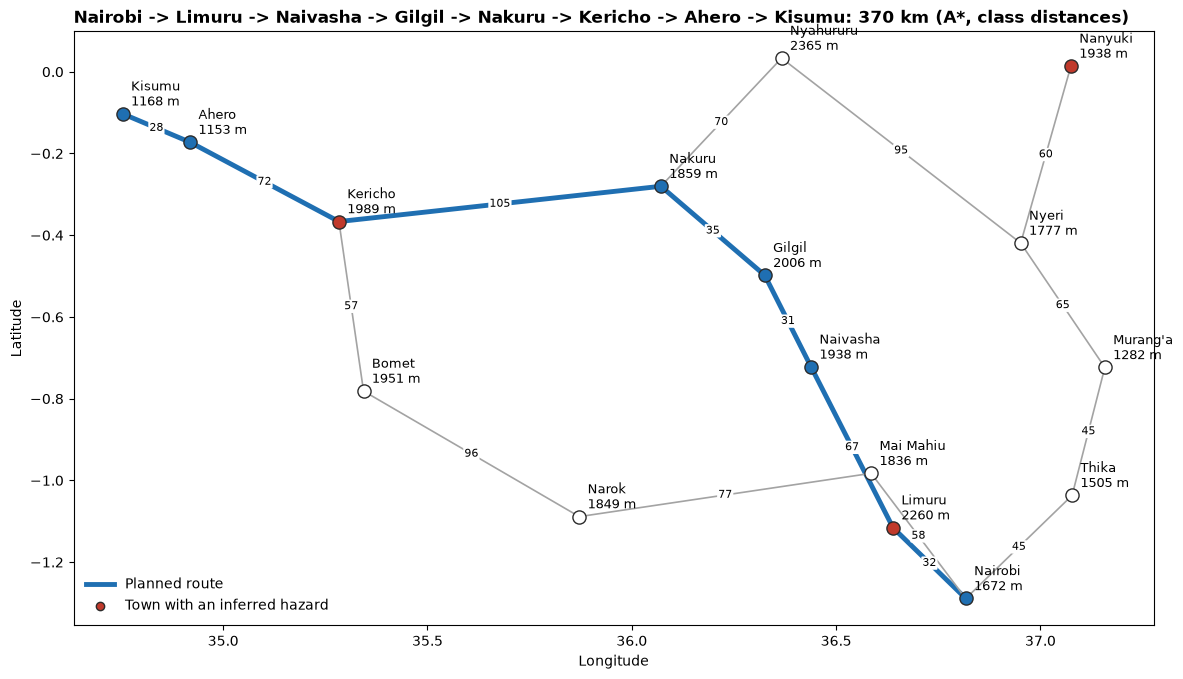

In [ ]:
def draw_plan(plan, title):
    """Network on real coordinates (Nominatim); planned route highlighted; hazards in red."""
    loc = {t: agent.location(t) for t in TOWNS}
    on_route = set(zip(plan["route"], plan["route"][1:]))
    fig, ax = plt.subplots(figsize=(12, 7))
    for b in kb.ask("Road", "?a", "?b", "?d"):
        a, z = b["?a"], b["?b"]
        used = (a, z) in on_route or (z, a) in on_route
        closed = bool(kb.ask("Closed", a, z))
        (y1, x1), (y2, x2) = loc[a], loc[z]
        ax.plot([x1, x2], [y1, y2], color="#1F6FB2" if used else "#A3A3A3",
                lw=3.5 if used else 1.2, ls=":" if closed else "-", zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, f"{b['?d']}", fontsize=8, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none"), zorder=2)
    hazard_towns = {f[1] for f in kb.facts if f[0] == "Hazard"}
    for town, (lat, lon) in loc.items():
        colour = "#C0392B" if town in hazard_towns else ("#1F6FB2" if town in plan["route"] else "white")
        ax.scatter(lon, lat, s=90, c=colour, edgecolors="#2B2B2B", zorder=3)
        ax.annotate(f"{town}\n{DATA['towns'][town]['elevation_m']} m", (lon, lat), xytext=(6, 6),
                    textcoords="offset points", fontsize=9, zorder=4)
    ax.plot([], [], color="#1F6FB2", lw=3.5, label="Planned route")
    ax.scatter([], [], c="#C0392B", edgecolors="#2B2B2B", label="Town with an inferred hazard")
    ax.legend(loc="lower left", frameon=False)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal")
    ax.set_title(title, loc="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


draw_plan(astar, f"{' -> '.join(astar['route'])}: {astar['km']} km ({astar['algorithm']}, class distances)")

**Talk to the agent.** Run the cell below to chat with the trailer. In Colab or Jupyter you can type any command from
`help`, and `quit` stops the chat. When the notebook runs without a keyboard (for example during an automated run), a short
scripted conversation is used instead.

In [ ]:
def chat(demo=()):
    print("Autonomous trailer ready. Type 'help' for commands, 'quit' to stop.")
    script = iter(demo)
    while True:
        try:
            text = input("you> ")
        except (EOFError, NotImplementedError, OSError):
            text = next(script, "quit")
            print(f"you> {text}")
        if text.strip().lower() in ("quit", "exit", "q"):
            print("Goodbye - drive safe.")
            break
        print(agent.answer(text), end="\n\n")


chat(demo=["help", "route to Narok", "speed Nyeri to Nyahururu", "why Nyeri to Nyahururu", "about Eldoret"])

Autonomous trailer ready. Type 'help' for commands, 'quit' to stop.
you> help
Commands (town names are case-insensitive):
  route [from] A to B [safest] [ucs] [osrm]   plan a trip (default: shortest, A*, class distances)
  speed A to B          legal and safe speed on a road
  why A to B | why A | why ready     explain the agent's conclusions
  about A               what the KB knows about a town
  weather [at] A        weather and hazards at a town
  report <condition> at A | clear weather at A   add or remove a weather report
  close A to B | open A to B         report a road closure / reopening
  signal <colour>       what to do at a traffic light
  load <kg> | status    set the gross vehicle mass / check readiness to depart
  facts                 summary of the knowledge base

you> route to Narok
TRIP PLAN (shortest, UCS, class distances)
Route: Nairobi -> Mai Mahiu -> Narok
                 Leg  km  km/h  min                                                                   Advic

**Step 9: Debugging the Knowledge Base** `[2 marks]`

Debugging has two parts:

1. **Behavioural tests.** Feed the agent unknown towns, unknown signals, impossible requests and a fully cut-off
   start town, and check that it answers safely instead of crashing or guessing.
2. **Consistency checks on the knowledge itself.** Compare the three distance measures and the graph structure
   to find facts that cannot all be true.

In [ ]:
print("--- Behavioural tests ---")
converse([
    "route Nairobi to Mombasa",       # unknown town
    "route Kisumu to Kisumu",         # already there
    "speed Nairobi to Kisumu",        # no direct road
    "close Nairobi to Kisumu",        # road that does not exist
    "report snow at Nyeri",           # condition outside the vocabulary
    "signal blue",                    # unknown signal -> safe default
    "make me a coffee",               # not a command
])

print("--- Cut off the start town: every road out of Nairobi closed ---")
for town in ("Thika", "Limuru", "Mai Mahiu"):
    agent.answer(f"close Nairobi to {town}")
print(agent.answer("route Nairobi to Kisumu"))
for town in ("Thika", "Limuru", "Mai Mahiu"):
    agent.answer(f"open Nairobi to {town}")
print(agent.answer("route Nairobi to Kisumu").splitlines()[1], "(roads reopened)")

--- Behavioural tests ---
you> route Nairobi to Mombasa
I have no knowledge of: Mombasa.

you> route Kisumu to Kisumu
The trailer is already at Kisumu.

you> speed Nairobi to Kisumu
There is no passable road from Nairobi to Kisumu.

you> close Nairobi to Kisumu
There is no road between Nairobi and Kisumu in the knowledge base.

you> report snow at Nyeri
Use: report <condition> at <town>. Known conditions: Clear, Cloudy, Drizzle, Rain, HeavyRain, Fog, Thunderstorm, StrongWind, LowVisibility.

you> signal blue
Signal Blue: Unknown signal - treat as a hazard: stop safely and wait.

you> make me a coffee
Sorry, I don't understand 'make me a coffee'. Type 'help'.

--- Cut off the start town: every road out of Nairobi closed ---
No passable route from Nairobi to Kisumu.
Route: Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru -> Kericho -> Ahero -> Kisumu (roads reopened)


In [ ]:
loc = {t: agent.location(t) for t in TOWNS}
rows = []
for road in DATA["roads"]:
    a, b, km, osrm = road["a"], road["b"], road["km_class"], road["km_osrm"]
    line = haversine(loc[a], loc[b])
    issues = []
    if km < line:
        issues.append("class km < straight line (impossible)")
    if abs(osrm - km) / km > 0.25:
        issues.append(f"OSRM differs by {round((osrm - km) / km * 100)}%")
    rows.append([f"{a} - {b}", km, osrm, round(line, 1), "; ".join(issues) or "ok"])
checks = pd.DataFrame(rows, columns=["Road", "Class km", "OSRM km", "Straight km", "Check"])
print("Check 1 - the three distance measures for every road:")
display(checks[checks["Check"] != "ok"])
print(f"{(checks['Check'] == 'ok').sum()} of {len(checks)} roads pass both checks.\n")

graph = agent.graph()
bad_goals = [g for g in TOWNS if not is_consistent(graph, lambda a, b, d: d, lambda s: haversine(loc[s], loc[g]))]
print("Check 2 - goals for which the haversine heuristic is inconsistent:", ", ".join(bad_goals) or "none")

reachable, stack = set(), ["Nairobi"]
while stack:
    town = stack.pop()
    if town not in reachable:
        reachable.add(town)
        stack += list(graph.get(town, {}))
print("Check 3 - towns unreachable from Nairobi:", ", ".join(sorted(set(TOWNS) - reachable)) or "none")

missing = [t for t in TOWNS if not (kb.ask("Location", t, "?a", "?b") and kb.ask("Elevation", t, "?e"))]
print("Check 4 - towns missing a location or elevation:", ", ".join(missing) or "none")

Check 1 - the three distance measures for every road:


,Road,Class km,OSRM km,Straight km,Check
9,Gilgil - Nakuru,35,41.7,37.2,class km < straight line (impossible)
12,Mai Mahiu - Narok,77,89.3,80.3,class km < straight line (impossible)
14,Bomet - Kericho,57,77.4,46.6,OSRM differs by 36%


14 of 17 roads pass both checks.

Check 2 - goals for which the haversine heuristic is inconsistent: Gilgil, Limuru, Mai Mahiu, Murang'a, Nairobi, Naivasha, Nakuru, Narok, Thika
Check 3 - towns unreachable from Nairobi: none
Check 4 - towns missing a location or elevation: none


**What the checks found, and how the KB was fixed**

* **Geocoding bug (found and fixed in `build_kb.py`).** The first version of `build_kb.py` took Nominatim's first
  result. For at least five towns (Narok, Bomet, Kericho, Murang'a and Nyeri) that was the *county boundary*, not the town; Narok's
  county centroid is about 45 km from the town. Check 1 then reported Mai Mahiu-Narok as 77 km by road but 127 km in a straight
  line, which is impossible. The builder now accepts only results that OSM addresses as a city, town or village.
* **Class distances.** After the fix, a couple of class distances are still slightly *shorter* than the straight line
  between the town centres (see the table above), and Bomet-Kericho is about a third shorter than OSRM's
  driving distance. These are approximations in the Exercise 3 graph. The agent keeps the class distances as
  its default, for continuity with Exercise 3, and offers OSRM as a second measure.
* **Heuristic safety.** Because of those short edges, the straight-line heuristic is inconsistent for some goals (check 2).
  `plan()` detects this before searching and falls back to UCS, so the agent never returns a non-optimal route.
* **Robustness of the main conclusion.** The cell below re-plans the trip with the real OSRM distances. If the
  northern corridor is still chosen, the Exercise 3 decision does not depend on the approximate class weights.

In [ ]:
osrm_plan = agent.plan(start, goal, measure="osrm")
print(agent.briefing(osrm_plan))
print(f"\nClass-distance route: {' -> '.join(astar['route'])} ({astar['km']} km)")
print(f"OSRM-distance route:  {' -> '.join(osrm_plan['route'])} ({osrm_plan['km']} km)")
print("Same route under both distance measures:", osrm_plan["route"] == astar["route"])
print(f"OSRM door-to-door Nairobi -> Kisumu (its own best route): {DATA['osrm_nairobi_kisumu']['km']} km")

print("\nGoal with an inconsistent heuristic -> automatic fallback:")
print(agent.answer(f"route Nairobi to {bad_goals[0]}") if bad_goals else "none")

TRIP PLAN (shortest, A*, osrm distances)
Route: Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru -> Kericho -> Ahero -> Kisumu
               Leg    km  km/h  min                                                                                      Advice
 Nairobi -> Limuru  34.4    40   52            Long climb (588 m): keep left, watch engine temperature; LowVisibility at Limuru
Limuru -> Naivasha  57.2    40   86                            Accident blackspot (Kijabe escarpment): slow down, no overtaking
Naivasha -> Gilgil  31.0    80   23                                                                                           -
  Gilgil -> Nakuru  41.7    80   31                                                                                           -
 Nakuru -> Kericho 106.4    40  160 Accident blackspot (Salgaa - Sachang'wan stretch): slow down, no overtaking; Fog at Kericho
  Kericho -> Ahero  61.2    40   92                                             Long descent (836 m): lo

**Step 10: Add final reflection here (challenges or recommended improvements)** `[3 marks]`

**What the knowledge-based approach added to Exercise 3.** In Exercise 3 the trailer could only find the
shortest path on a fixed graph. Here the graph is *derived* from facts (`Road`, then `Arc`, then `Passable`), so
closures, weather and load change the agent's decisions without any change to the code. Every conclusion can
also be explained as a proof tree. The rules are separate from the search code, so the knowledge engineer can add a rule
(for example a new hazard type) without touching the planner.

**Challenges**

1. **Data quality from APIs.** Nominatim returned county centroids instead of towns for five of the 16 towns. The
   error was only caught because the KB was cross-checked against two other distance measures (Step 9). Automatically
   gathered knowledge must be validated, not trusted.
2. **Inconsistent hand-made knowledge.** Some Exercise 3 distances are shorter than the straight-line distance, which
   breaks the A\* optimality guarantee. The agent now checks heuristic consistency before every search.
3. **Point data along roads.** Weather and elevation are known only at the towns. The Kijabe escarpment, for example, lies
   *between* Limuru and Naivasha, so the town elevations (322 m apart) do not trigger the steep-grade rule. That
   blackspot had to be added by hand.
4. **Negation as failure.** `ReadyToDepart` and `Passable` rely on "cannot prove `Overloaded`/`Closed`". This is only
   sound if rules are ordered (stratified) so that the negated facts are derived first.
5. **Free-text interaction.** The command parser is simple, keyword and pattern based, so unusual phrasings are not
   understood.
6. **Usage limits.** Nominatim allows one request per second and the OSRM demo server is for light use only. So the static
   knowledge is cached in `kb_data.json` and only the weather is fetched live.

**Recommended improvements**

* Sample weather and elevation **along each road** (OSRM can return the road geometry) instead of only at the towns.
* Learn the `RiskPenalty` values from NTSA accident statistics instead of setting them by hand. Also add travel time
  as a third cost (OSRM provides it) for time-critical cargo.
* Add live traffic and incident feeds (e.g. KeNHA notices) so closures are learnt automatically, not reported.
* Replace the forward chainer with a production engine (e.g. `experta`) or a Prolog back end, and use
  backward chaining for one-off queries so the agent does not re-derive the whole KB after every TELL.
* Model uncertainty, since sensors and forecasts are noisy, with probabilities or certainty factors instead of true/false facts.
* Extend the vocabulary with more towns and roads, axle loads, bridge height and weight limits, and driver rest-hour rules.